# Training CLIP on COCO-Caption Dataset

This notebook demonstrates end-to-end training of a CLIP (Contrastive Language-Image Pre-training) model using:
- **Model**: OpenAI CLIP ViT-B/32 from HuggingFace
- **Dataset**: COCO-Caption2017 from HuggingFace datasets
- **Framework**: PyTorch with HuggingFace Transformers

## What You'll Learn
1. Loading and preparing vision-language datasets
2. Setting up CLIP model and processor
3. Implementing contrastive loss for CLIP
4. Training with best practices (mixed precision, gradient clipping, LR scheduling)
5. Evaluating and saving the trained model

## Prerequisites
```bash
pip install torch torchvision transformers datasets pillow tqdm matplotlib pyyaml
```

---

In [ ]:
%pip install -U torch torchvision transformers datasets pillow tqdm matplotlib pyyaml

In [1]:
from datasets import load_dataset

# downloadn 100 instances in streaming mode
ds = load_dataset("lmms-lab/COCO-Caption2017", split="val", streaming=True)

## Load COCO-Caption Dataset

We'll use a small subset of the COCO-Caption2017 dataset for demonstration.
The dataset contains images with multiple descriptive captions.

In [2]:
from tqdm import tqdm

N_SAMPLES = 50

ds_jsonl = [next(iter(ds)) for _ in tqdm(range(N_SAMPLES))]

ds_jsonl[0]

100%|██████████| 50/50 [00:32<00:00,  1.53it/s]


{'question_id': '000000179765.jpg',
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=640x480>,
 'question': 'Please carefully observe the image and come up with a caption for the image.',
 'answer': ['A black Honda motorcycle parked in front of a garage.',
  'A Honda motorcycle parked in a grass driveway',
  'A black Honda motorcycle with a dark burgundy seat.',
  'Ma motorcycle parked on the gravel in front of a garage',
  'A motorcycle with its brake extended standing outside'],
 'id': 38,
 'license': 3,
 'file_name': '000000179765.jpg',
 'coco_url': 'http://images.cocodataset.org/val2017/000000179765.jpg',
 'height': 480,
 'width': 640,
 'date_captured': '2013-11-15 14:02:51'}

In [3]:
from datasets import Dataset, DatasetDict

dds = DatasetDict({"train": Dataset.from_list(ds_jsonl)})

# split train-test 8-2
dds = dds["train"].train_test_split(test_size=0.2, seed=42)
dds

DatasetDict({
    train: Dataset({
        features: ['question_id', 'image', 'question', 'answer', 'id', 'license', 'file_name', 'coco_url', 'height', 'width', 'date_captured'],
        num_rows: 40
    })
    test: Dataset({
        features: ['question_id', 'image', 'question', 'answer', 'id', 'license', 'file_name', 'coco_url', 'height', 'width', 'date_captured'],
        num_rows: 10
    })
})

{
  "question_id": "000000179765.jpg",
  "question": "Please carefully observe the image and come up with a caption for the image.",
  "answer": [
    "A black Honda motorcycle parked in front of a garage.",
    "A Honda motorcycle parked in a grass driveway",
    "A black Honda motorcycle with a dark burgundy seat.",
    "Ma motorcycle parked on the gravel in front of a garage",
    "A motorcycle with its brake extended standing outside"
  ],
  "id": 38,
  "license": 3,
  "file_name": "000000179765.jpg",
  "coco_url": "http://images.cocodataset.org/val2017/000000179765.jpg",
  "height": 480,
  "width": 640,
  "date_captured": "2013-11-15 14:02:51"
}


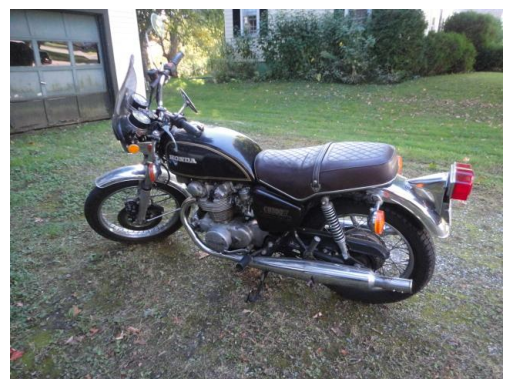

In [4]:
import json

print(json.dumps({k: dds["train"][0][k] for k in dds["train"][0] if k != "image"}, indent=2))

# visualize image
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

image = Image.fromarray(np.uint8(dds["train"][0]["image"]))
plt.imshow(image)
plt.axis("off")
plt.show()

In [5]:
## Setup: Install Required Packages

In [6]:
# Install required packages (uncomment if needed)
# !pip install torch torchvision transformers pillow tqdm datasets matplotlib pyyaml

# CLIP Training on COCO Dataset

This notebook demonstrates training a CLIP model using the COCO-Caption2017 dataset.

## Steps:
1. ✅ Load and prepare dataset
2. Setup CLIP model and processor
3. Configure training parameters
4. Train the model
5. Evaluate and save

## Step 1: Import Required Libraries

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.cuda.amp import GradScaler, autocast
from transformers import AutoModel, AutoProcessor, get_cosine_schedule_with_warmup
from tqdm.auto import tqdm
import time
import os

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Using device: cuda
GPU: Tesla T4
Memory: 15.83 GB


## Step 2: Prepare Dataset for Training

In [8]:
from torch.utils.data import Dataset
from PIL import Image

class COCOCLIPDataset(Dataset):
    """Dataset wrapper for COCO with CLIP preprocessing."""

    def __init__(self, hf_dataset, processor):
        self.dataset = hf_dataset
        self.processor = processor

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]

        # Get image and convert to PIL if needed
        image = item['image']
        if not isinstance(image, Image.Image):
            image = Image.fromarray(image)

        # Get caption - COCO-Caption2017 uses 'caption' key (not 'sentences')
        caption = item['answer'][0]

        # If caption is a list, take the first one
        if isinstance(caption, list):
            caption = caption[0]

        return image, caption

def collate_fn(batch, processor):
    """Collate function to process batch with CLIP processor."""
    images, texts = zip(*batch)

    # Process with HuggingFace processor
    inputs = processor(
        text=list(texts),
        images=list(images),
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    return inputs

# Create datasets
train_dataset = COCOCLIPDataset(dds['train'], None)  # We'll set processor later
test_dataset = COCOCLIPDataset(dds['test'], None)

print(f"Train dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

Train dataset size: 40
Test dataset size: 10


## Step 3: Load CLIP Model and Processor

In [9]:
from transformers import AutoModel, AutoProcessor

# Model configuration
model_name = "facebook/metaclip-b32-400m"
print(f"Loading model: {model_name}")

# Load processor
processor = AutoProcessor.from_pretrained(model_name)

Loading model: facebook/metaclip-b32-400m


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


In [10]:
import torch
# Load model
model = AutoModel.from_pretrained(model_name, torch_dtype=torch.float32)
model = model.to(device)

# Update datasets with processor
train_dataset.processor = processor
test_dataset.processor = processor

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params / 1e6:.2f}M")
print(f"Trainable parameters: {trainable_params / 1e6:.2f}M")
print(f"Model loaded successfully!")

`torch_dtype` is deprecated! Use `dtype` instead!



Total parameters: 151.28M
Trainable parameters: 151.28M
Model loaded successfully!


## Step 4: Define Loss Function and Metrics

In [25]:
class CLIPLoss(nn.Module):
    """Contrastive loss for CLIP training."""

    def __init__(self):
        super().__init__()

    def forward(self, logits_per_image, logits_per_text):
        """
        Compute symmetric cross-entropy loss.

        Args:
            logits_per_image: [batch_size, batch_size] similarity matrix
            logits_per_text: [batch_size, batch_size] similarity matrix
        """
        labels = torch.arange(logits_per_image.shape[0], device=logits_per_image.device)

        loss_i = F.cross_entropy(logits_per_image, labels)
        loss_t = F.cross_entropy(logits_per_text, labels)

        print("Loss image", loss_i,"Loss text",loss_t)

        return (loss_i + loss_t) / 2

class AverageMeter:
    """Computes and stores the average and current value."""

    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

# Initialize loss
criterion = CLIPLoss()
print("Loss function initialized")

Loss function initialized


## Step 5: Configure Training Parameters

In [21]:
# Training configuration
config = {
    'batch_size': 4,  # Small batch for demo dataset
    'num_epochs': 10,
    'learning_rate': 2e-3,
    'weight_decay': 0.01,
    'warmup_ratio': 0.1,
    'max_grad_norm': 1.0,
    'num_workers': 2,
    'log_interval': 5,
    'output_dir': './checkpoints/coco_clip',
}

# Create output directory
os.makedirs(config['output_dir'], exist_ok=True)

# Create dataloaders
train_dataloader = DataLoader(
    train_dataset,
    batch_size=config['batch_size'],
    shuffle=True,
    num_workers=config['num_workers'],
    collate_fn=lambda batch: collate_fn(batch, processor),
    pin_memory=True
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config['num_workers'],
    collate_fn=lambda batch: collate_fn(batch, processor),
    pin_memory=True
)

print("Configuration:")
for key, value in config.items():
    print(f"  {key}: {value}")
print(f"\nTrain batches: {len(train_dataloader)}")
print(f"Test batches: {len(test_dataloader)}")

Configuration:
  batch_size: 4
  num_epochs: 10
  learning_rate: 0.002
  weight_decay: 0.01
  warmup_ratio: 0.1
  max_grad_norm: 1.0
  num_workers: 2
  log_interval: 5
  output_dir: ./checkpoints/coco_clip

Train batches: 10
Test batches: 3


## Step 6: Setup Optimizer and Scheduler

In [22]:
# Setup optimizer with weight decay
# Separate parameters: no weight decay for biases and layer norms
no_decay = ['bias', 'LayerNorm.weight', 'layernorm.weight', 'ln', 'bn']
optimizer_grouped_parameters = [
    {
        'params': [p for n, p in model.named_parameters()
                  if not any(nd in n for nd in no_decay) and p.requires_grad],
        'weight_decay': config['weight_decay']
    },
    {
        'params': [p for n, p in model.named_parameters()
                  if any(nd in n for nd in no_decay) and p.requires_grad],
        'weight_decay': 0.0
    }
]

optimizer = torch.optim.AdamW(
    optimizer_grouped_parameters,
    lr=config['learning_rate'],
    betas=(0.9, 0.98),
    eps=1e-6
)

# Calculate training steps
total_steps = len(train_dataloader) * config['num_epochs']
warmup_steps = int(total_steps * config['warmup_ratio'])

# Setup learning rate scheduler
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print(f"Optimizer: AdamW")
print(f"Total training steps: {total_steps}")
print(f"Warmup steps: {warmup_steps}")
print(f"Scheduler: Cosine with warmup")

Optimizer: AdamW
Total training steps: 100
Warmup steps: 10
Scheduler: Cosine with warmup


## Step 7: Training Loop

In [23]:
# Assert that gradients are enabled for all parameters
for name, param in model.named_parameters():
    assert param.requires_grad, f"Parameter {name} does not require gradients!"

In [ ]:
# Training function
def train_epoch(model, dataloader, criterion, optimizer, scheduler, device, epoch, config):
    """Train for one epoch."""
    model.train()
    loss_meter = AverageMeter()
    grad_norm_meter = AverageMeter()
    scaler = GradScaler() # Initialize GradScaler for mixed precision

    # Add tqdm for progress bar
    progress_bar = tqdm(dataloader, desc=f"Epoch {epoch+1}/{config['num_epochs']}")

    for batch_idx, inputs in enumerate(progress_bar):
        # Move inputs to device
        inputs = {k: v.to(device, non_blocking=True) for k, v in inputs.items()}

        # Zero gradients
        optimizer.zero_grad()

        # Forward pass with autocast for mixed precision
        with autocast():
            outputs = model(**inputs)
            logits_per_image = outputs.logits_per_image
            logits_per_text = outputs.logits_per_text
            print(f"logits_per_image: {logits_per_image.shape}")
            print(f"logits_per_text: {logits_per_text.shape}")

            loss = criterion(logits_per_image, logits_per_text)

        # Backward pass with GradScaler
        scaler.scale(loss).backward()

        # Gradient clipping
        if config['max_grad_norm'] > 0:
            # Unscale gradients before clipping
            scaler.unscale_(optimizer)
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), config['max_grad_norm']).item()
            grad_norm_meter.update(grad_norm)

        # print gradients
        #for name, param in model.named_parameters():
        #    if param.grad is not None:
        #       print(f"{name}: {param.grad.norm().item()}")

        # Optimizer step with GradScaler
        scaler.step(optimizer)
        scaler.update() # Update the scaler for the next iteration
        scheduler.step()

        # Update metrics
        loss_meter.update(loss.item(), inputs['pixel_values'].size(0))


        # Update progress bar
        progress_bar.set_postfix({
            'loss': f'{loss_meter.avg:.8f}',
            'lr': f'{scheduler.get_last_lr()[0]:.6f}',
            'grad_norm': f'{grad_norm_meter.avg:.4f}'
        })

    return loss_meter.avg

# Start training
print("Starting training...")
print("=" * 80)

training_history = {
    'train_loss': [],
    'learning_rates': []
}

best_loss = float('inf')

for epoch in range(config['num_epochs']):
    epoch_start = time.time()

    # Train for one epoch
    train_loss = train_epoch(
        model, train_dataloader, criterion, optimizer,
        scheduler, device, epoch, config
    )

    training_history['train_loss'].append(train_loss)
    training_history['learning_rates'].append(scheduler.get_last_lr()[0])

    epoch_time = time.time() - epoch_start

    print(f"\nEpoch {epoch+1}/{config['num_epochs']} completed in {epoch_time:.2f}s")
    print(f"Average Loss: {train_loss:.4f}")
    print(f"Learning Rate: {scheduler.get_last_lr()[0]:.6f}")

## Step 8: Visualize Training Progress

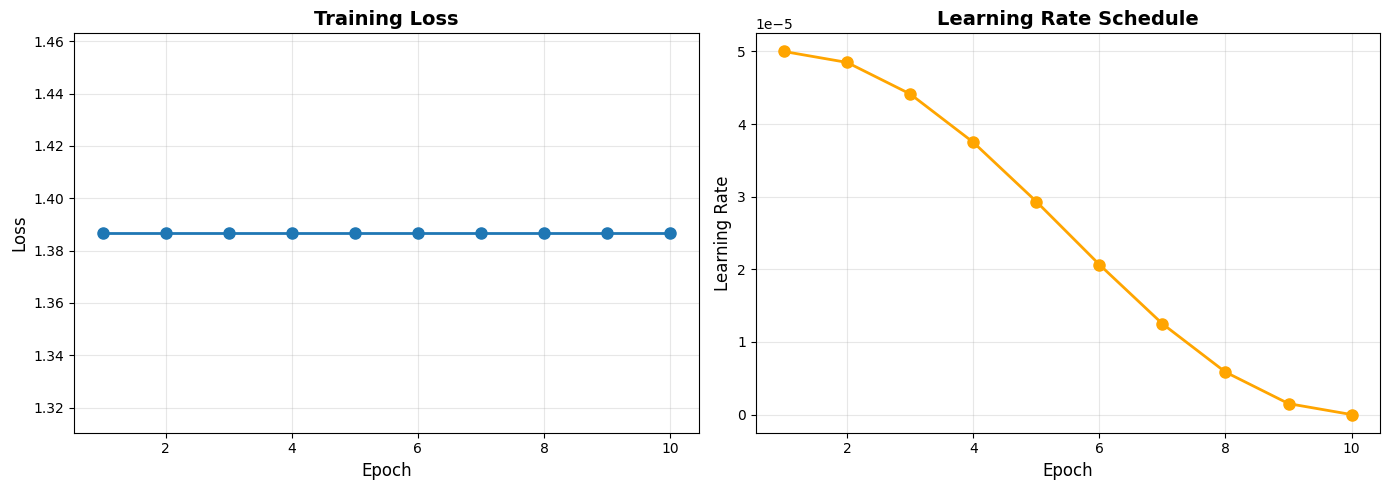


Final Training Loss: 1.3867
Best Training Loss: 1.3867


In [16]:
import matplotlib.pyplot as plt

# Plot training loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss curve
ax1.plot(range(1, len(training_history['train_loss']) + 1),
         training_history['train_loss'],
         marker='o', linewidth=2, markersize=8)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('Training Loss', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Learning rate curve
ax2.plot(range(1, len(training_history['learning_rates']) + 1),
         training_history['learning_rates'],
         marker='o', linewidth=2, markersize=8, color='orange')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Learning Rate', fontsize=12)
ax2.set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nFinal Training Loss: {training_history['train_loss'][-1]:.4f}")
print(f"Best Training Loss: {min(training_history['train_loss']):.4f}")

## Step 9: Evaluate on Test Set

In [17]:
def evaluate(model, dataloader, criterion, device):
    """Evaluate model on test set."""
    model.eval()
    loss_meter = AverageMeter()

    with torch.no_grad():
        for inputs in tqdm(dataloader, desc="Evaluating"):
            # Move inputs to device
            inputs = {k: v.to(device, non_blocking=True) for k, v in inputs.items()}

            # Forward pass
            outputs = model(**inputs)
            logits_per_image = outputs.logits_per_image
            logits_per_text = outputs.logits_per_text

            loss = criterion(logits_per_image, logits_per_text)

            # Update metrics
            loss_meter.update(loss.item(), inputs['pixel_values'].size(0))

    return loss_meter.avg

# Evaluate on test set
print("Evaluating on test set...")
test_loss = evaluate(model, test_dataloader, criterion, device)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Train Loss: {training_history['train_loss'][-1]:.4f}")
print(f"Difference: {abs(test_loss - training_history['train_loss'][-1]):.4f}")

Evaluating on test set...


Evaluating:   0%|          | 0/3 [00:00<?, ?it/s]


Test Loss: 1.2477
Train Loss: 1.3867
Difference: 0.1391


## Step 10: Test the Trained Model

Image Caption: A black Honda motorcycle parked in front of a garage.

Similarity scores:
  1.0000 - A black Honda motorcycle parked in front of a garage.
  0.0000 - a photo of a dog
  0.0000 - a photo of a cat
  0.0000 - a photo of a car
  0.0000 - a photo of a person


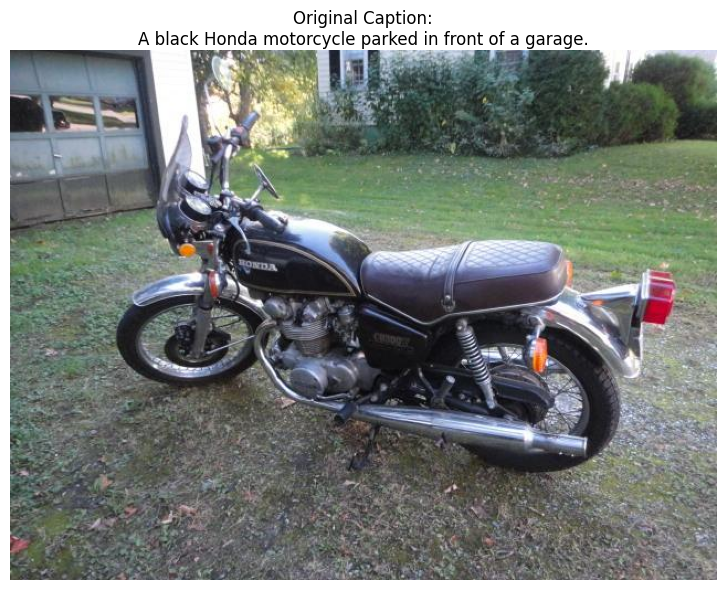


Best match: A black Honda motorcycle parked in front of a garage.
Confidence: 1.0000


In [18]:
# Test the model with a sample from the test set
model.eval()

# Get a sample
sample_idx = 0
sample_image, sample_caption = test_dataset[sample_idx]

# Test with multiple captions
test_captions = [
    sample_caption,
    "a photo of a dog",
    "a photo of a cat",
    "a photo of a car",
    "a photo of a person"
]

# Process inputs
inputs = processor(
    text=test_captions,
    images=[sample_image] * len(test_captions),
    return_tensors="pt",
    padding=True
).to(device)

# Get predictions
with torch.no_grad():
    outputs = model(**inputs)
    logits_per_image = outputs.logits_per_image
    probs = logits_per_image.softmax(dim=1)[0]

# Display results
print("Image Caption:", sample_caption)
print("\nSimilarity scores:")
for caption, prob in zip(test_captions, probs):
    print(f"  {prob.item():.4f} - {caption}")

# Visualize the image
plt.figure(figsize=(8, 6))
plt.imshow(sample_image)
plt.axis('off')
plt.title(f"Original Caption:\n{sample_caption}", fontsize=12, wrap=True)
plt.tight_layout()
plt.show()

# Show top prediction
best_idx = probs.argmax().item()
print(f"\nBest match: {test_captions[best_idx]}")
print(f"Confidence: {probs[best_idx].item():.4f}")